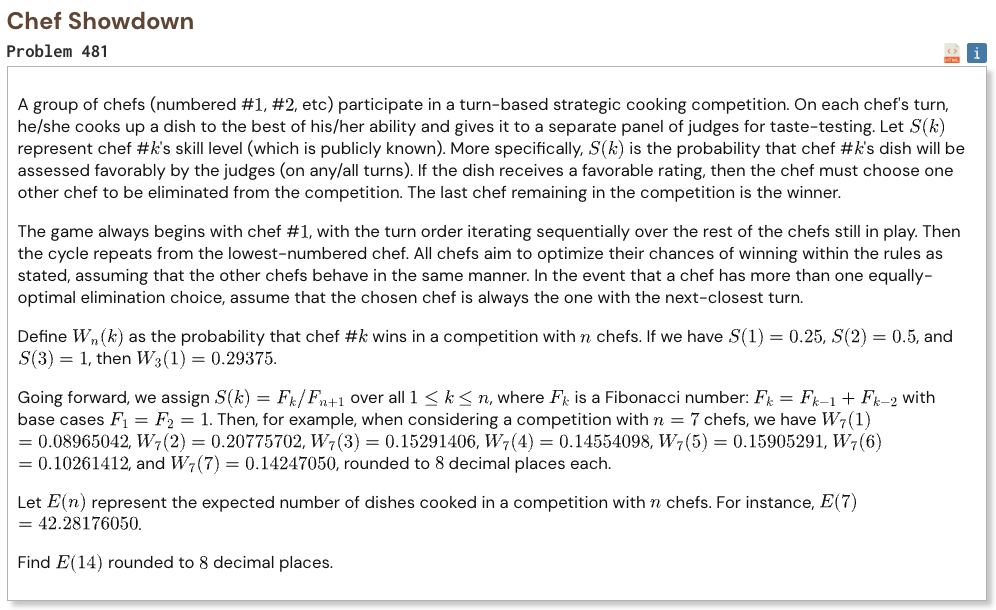

## Initial approach

- represent each game state by the chefs still alive and whose turn it is
- solve smaller groups first so every possible elimination result is already known
- for each chef, choose the opponent whose removal gives the best chance of eventually winning
- use the next closest turn rule when two elimination choices are equally good
- solve the cyclic turn probabilities for each surviving group
- track the expected remaining number of dishes with the same state transitions
- repeat for all subsets up to 14 chefs and read the expectation from the full starting state

In [1]:
%%time

N = 14

fib = [0] * (N + 2)
fib[1] = fib[2] = 1

for i in range(3, N + 2):
    fib[i] = fib[i - 1] + fib[i - 2]

skill = [
    fib[i + 1] / fib[N + 1]
    for i in range(N)
]

size = 1 << N

win = [None] * size
expected = [None] * size

for chef in range(N):
    mask = 1 << chef

    states = [None] * N
    values = [0.0] * N
    values[chef] = 1.0

    states[chef] = values

    win[mask] = states
    expected[mask] = [0.0] * N

def next_chef(mask, chef):
    for distance in range(1, N + 1):
        candidate = (chef + distance) % N

        if mask & (1 << candidate):
            return candidate

for count in range(2, N + 1):
    for mask in range(1, size):
        if mask.bit_count() != count:
            continue

        chefs = [
            i
            for i in range(N)
            if mask & (1 << i)
        ]

        success_win = []
        success_expected = []
        failure = []

        for chef in chefs:
            best_value = -1.0
            best_distance = N + 1
            best_win = None
            best_expected = None

            for target in chefs:
                if target == chef:
                    continue

                next_mask = mask ^ (1 << target)
                turn = next_chef(next_mask, chef)

                value = win[next_mask][turn][chef]
                distance = (target - chef) % N

                if (
                    value > best_value + 1e-14
                    or (
                        abs(value - best_value) <= 1e-14
                        and distance < best_distance
                    )
                ):
                    best_value = value
                    best_distance = distance
                    best_win = win[next_mask][turn]
                    best_expected = expected[next_mask][turn]

            success_win.append(best_win)
            success_expected.append(best_expected)
            failure.append(1 - skill[chef])

        product = 1.0
        win_total = [0.0] * N
        expected_total = 0.0

        for index, chef in enumerate(chefs):
            probability = skill[chef]

            for k in range(N):
                win_total[k] += (
                    product
                    * probability
                    * success_win[index][k]
                )

            expected_total += (
                product
                * (
                    1
                    + probability
                    * success_expected[index]
                )
            )

            product *= failure[index]

        denominator = 1 - product

        first_win = [
            value / denominator
            for value in win_total
        ]

        first_expected = expected_total / denominator

        win_states = [None] * N
        expected_states = [0.0] * N

        win_states[chefs[0]] = first_win
        expected_states[chefs[0]] = first_expected

        next_win = first_win
        next_expected = first_expected

        for index in range(len(chefs) - 1, 0, -1):
            chef = chefs[index]
            probability = skill[chef]

            current_win = [
                probability * success_win[index][k]
                + failure[index] * next_win[k]
                for k in range(N)
            ]

            current_expected = (
                1
                + probability * success_expected[index]
                + failure[index] * next_expected
            )

            win_states[chef] = current_win
            expected_states[chef] = current_expected

            next_win = current_win
            next_expected = current_expected

        win[mask] = win_states
        expected[mask] = expected_states

result = expected[(1 << N) - 1][0]

print("Result:", f"{result:.8f}")

Result: 729.12106947
CPU times: user 643 ms, sys: 11.3 ms, total: 654 ms
Wall time: 654 ms
